# NB15 - Category Theory as RELIC's Design Language

> **Goal**: Understand how category theory organises RELIC's architecture
> and which RELIC checks make a Functor composition valid.

## Learning Objectives

1. **Objects & Morphisms** -- Reservoirs and Fields as objects, Functors as morphisms
2. **Spatial Scale Lattice** -- Why scale is a partial order, not just a number
3. **Product Category S x T** -- Combining space and time scales
4. **Aggregation and Disaggregation** -- Weighted adjoints: $RP = I$, $PR \neq I$
5. **Functor Composition** -- What associativity gives and what RELIC checks

### Prerequisites

- NB01 (Minimal RELIC Run) for FunctorBase concepts
- NB13-14 for DEC / topological context

### Key References

- Mac Lane (1998), *Categories for the Working Mathematician*
- Spivak (2014), *Category Theory for the Sciences*
- `docs/source/theory/spatiotemporal_scale_topology.md` (which statements are implemented
  and which are design interpretations)
- RELIC `category_theory.py` (design blueprint, not imported at runtime)


## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


In [1]:
# Event loop compatibility patch for nbconvert/Jupyter execution
import asyncio
if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

# ---------------------------------------------------------------
# References:
#   Farquhar et al. (1980), Planta -- C3 biochemical photosynthesis model.
#   Mac Lane (1998), Categories for the Working Mathematician, Ch. IV.
#   RELIC architecture_overview.md and coupling/scales modules.
# Mathematical expression:
#   A_net = min(Ac, Aj) - Rd
#   phi_daily = Agg(phi_hourly)
#   phi_hourly = Dis(phi_daily)
# Parameter meanings:
#   par_hourly: hourly photosynthetically active radiation forcing [umol m-2 s-1]
#   temperature_hourly: hourly air temperature forcing [K]
#   patch_areas: patch area weights for spatial aggregation
# Units: PAR [umol m-2 s-1]; temperature [K]; GPP [kg C m-2 s-1] (area density);
#   patch_areas [m2], a declared 1 m2 total support; time coordinates [hours].
# Domain/constraints: hourly and daily intervals are explicit half-open bounds; the valid
#   coverage threshold is the parameter coupling.scales.temporal.coverage_threshold.
# Sign convention: GPP >= 0 is carbon uptake by the canopy.
# ---------------------------------------------------------------

from pathlib import Path
import os
import sys
import warnings
import logging

os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'


def locate_project_root() -> Path:
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents, Path(os.environ.get('RELIC_PROJECT_ROOT', Path.cwd())).resolve()]
    for candidate in candidates:
        if (candidate / 'relic').is_dir() and (candidate / 'docs' / 'source' / 'architecture_overview.md').is_file():
            return candidate
    raise FileNotFoundError('Could not locate RELIC project root from the active notebook environment.')


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

warnings.filterwarnings('ignore', category=FutureWarning, module=r'torch\\cuda')
warnings.filterwarnings('ignore', message=r'The pynvml package is deprecated.*')
warnings.filterwarnings('ignore', message=r'Consolidated metadata is currently not part in the Zarr format 3 specification.*')

import matplotlib.pyplot as plt
import torch

from relic.parameters import get_global_manager
from relic.core.state import StateManager, UpdateItem
from relic.core.constants import get_scale_hierarchy
from relic.core.functor.functor_types import SpatialScale, TemporalScale
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis
from relic.scientific.hydrosphere.evapotranspiration.penman_monteith import PenmanMonteithET
from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture
from relic.scientific.hydrosphere.runoff.subsurface import SubsurfaceRunoff
from relic.coupling.scales.scale_manager import ScaleManager
from relic.coupling.scales.types import ScalingStrategy, SpatialQuantityBasis
from relic.coupling.scales.temporal.types import TemporalConfig, TemporalSemantics, ScalingDirection, ConservationLevel
from relic.coupling.scales.temporal.aggregator import TemporalAggregator, AggregationConfig, AggregationMethod
from relic.coupling.scales.temporal.disaggregator import TemporalDisaggregator, DisaggregationConfig, DisaggregationMethod
from relic.coupling.protocol.state import State
from relic.coupling.protocol.field import Field
from relic.coupling.protocol.mediator import Mediator
from relic.coupling.protocol.time_stagger import TimeStagger, ClockConfig, TimeUnit

for logger_name in [
    'relic.coupling.scales.hierarchical_strategies',
    'relic.coupling.scales.hierarchical.aggregator',
    'relic.coupling.scales.scale_manager',
]:
    logging.getLogger(logger_name).setLevel(logging.ERROR)

parameter_manager = get_global_manager()
scale_hierarchy = get_scale_hierarchy(parameter_manager)
scale_state_manager = StateManager()
# The facade ledger tolerance is coupling.scales.defaults.precision.<mode>.tolerance of each
# call's mode (ScaleManager.ledger_tolerance); the constructor takes no tolerance.
scale_manager_runtime = ScaleManager(
    device=torch.device('cpu'),
    parameter_manager=parameter_manager,
    state_manager=scale_state_manager,
)
scale_manager_runtime.ensure_ready()
execution_plan_manifest = scale_manager_runtime.execution_plan()
farquhar_warning_counts: dict[str, int] = {}


def build_photosynthesis_state(par, temperature, leaf_area_index=3.0, co2_ppm: float = 410.0) -> dict:
    par_t = torch.as_tensor(par, dtype=torch.float32).reshape(-1)
    temperature_t = torch.as_tensor(temperature, dtype=torch.float32).reshape(-1)
    lai_t = torch.as_tensor(leaf_area_index, dtype=torch.float32).reshape(-1)
    if lai_t.numel() == 1 and par_t.numel() > 1:
        lai_t = lai_t.repeat(par_t.numel())
    co2_t = torch.full_like(par_t, float(co2_ppm))
    ones = torch.ones_like(par_t)
    return {
        'air_temperature': temperature_t,
        'atmospheric_co2_ppm': co2_t,
        'ppfd': par_t,
        'vcmax_scaling': ones,
        'jmax_scaling': ones,
        'water_stress_factor': ones,
        'temperature_stress_factor': ones,
        'ozone_stress_factor': ones,
        'leaf_area_index': lai_t,
        'vapor_pressure_deficit': torch.full_like(par_t, 1000.0),
        'leaf_water_potential': torch.full_like(par_t, -0.3),
    }


def run_farquhar_response(par, temperature, leaf_area_index=3.0, name='nb15_farquhar_run') -> dict:
    par_t = torch.as_tensor(par, dtype=torch.float32)
    original_shape = par_t.shape
    functor = FarquharPhotosynthesis(
        name=name,
        vcmax25=58.0,
        jmax25=112.0,
        rd25=1.6,
        device=torch.device('cpu'),
        enable_gpu=False,
    )
    with warnings.catch_warnings(record=True) as caught_farquhar_warnings:
        warnings.simplefilter('always', UserWarning)
        # Governed call: FunctorBase.__call__ runs the kernel and its local checks.
        outputs = functor(
            build_photosynthesis_state(par_t, temperature, leaf_area_index=leaf_area_index),
            time=0.0,
            dt=3600.0,
        )
    if caught_farquhar_warnings:
        farquhar_warning_counts[name] = farquhar_warning_counts.get(name, 0) + len(caught_farquhar_warnings)
    return {
        key: torch.as_tensor(value.value if isinstance(value, UpdateItem) else value, dtype=torch.float32).reshape(original_shape).detach().cpu()
        for key, value in outputs.items()
    }


farquhar_functor = FarquharPhotosynthesis(
    name='nb15_farquhar_photosynthesis',
    vcmax25=58.0,
    jmax25=112.0,
    rd25=1.6,
    device=torch.device('cpu'),
    enable_gpu=False,
)
# canopy_resistance_source='state': the canopy resistance comes from the surface_resistance
# (or canopy_conductance) state, as for a vegetated surface rather than FAO-56 reference grass.
penman_functor = PenmanMonteithET(
    name='nb15_penman_monteith_et',
    config={'canopy_resistance_source': 'state'},
)
bucket_functor = BucketSoilMoisture(name='nb15_bucket_soil_moisture')
subsurface_functor = SubsurfaceRunoff(name='nb15_subsurface_runoff')

days = 30
hours = days * 24
# Centered hourly and daily coordinates keep RELIC temporal bounds aligned with interval means.
hourly_time = torch.arange(hours, dtype=torch.float32) + 0.5
daily_time = (torch.arange(days, dtype=torch.float32) + 0.5) * 24.0
hourly_bounds = torch.stack([torch.arange(hours, dtype=torch.float32), torch.arange(1, hours + 1, dtype=torch.float32)], dim=1)
daily_bounds = torch.stack([torch.arange(days, dtype=torch.float32) * 24.0, torch.arange(1, days + 1, dtype=torch.float32) * 24.0], dim=1)

hour_fraction = torch.remainder((hourly_time - 0.5) / 24.0, 1.0)
seasonal_factor = 0.85 + 0.15 * torch.sin(2.0 * torch.pi * torch.arange(hours, dtype=torch.float32) / hours)
solar_cycle = torch.clamp(torch.sin(torch.pi * hour_fraction), min=0.0)
par_hourly = 120.0 + 1350.0 * torch.pow(solar_cycle, 1.2) * seasonal_factor
temperature_hourly = 295.0 + 6.5 * torch.sin(2.0 * torch.pi * hour_fraction - 0.6) + 1.5 * torch.sin(2.0 * torch.pi * torch.arange(hours, dtype=torch.float32) / hours)

temporal_outputs = run_farquhar_response(
    par=par_hourly,
    temperature=temperature_hourly,
    leaf_area_index=3.1,
    name='nb15_temporal_series',
)
gpp_hourly_rate = temporal_outputs['gross_primary_productivity']
daily_temperature_mean = temperature_hourly.reshape(days, 24).mean(dim=1)

# Explicit cell areas in m2; their sum is the target support area, not a flux multiplier.
patch_areas = torch.tensor([0.30, 0.20, 0.35, 0.15], dtype=torch.float32)
patch_par = torch.tensor([1100.0, 1425.0, 980.0, 1280.0], dtype=torch.float32)
patch_temperature = torch.tensor([298.0, 300.0, 297.0, 299.0], dtype=torch.float32)
patch_lai = torch.tensor([2.7, 3.5, 2.3, 3.1], dtype=torch.float32)
patch_outputs = run_farquhar_response(
    par=patch_par,
    temperature=patch_temperature,
    leaf_area_index=patch_lai,
    name='nb15_patch_flux',
)
patch_gpp = patch_outputs['gross_primary_productivity']

# Regular hourly samples represent interval means, so arithmetic mean is the correct daily mean operator.
# The valid-coverage threshold is read from coupling.scales.temporal.coverage_threshold when an
# aggregator is constructed; it is not a TemporalConfig field and is not overridden here.
gpp_rate_aggregator = TemporalAggregator(
    TemporalConfig(
        source_frequency='hourly',
        target_frequency='daily',
        direction=ScalingDirection.UPSCALE,
        spatial_basis=SpatialQuantityBasis.AREA_DENSITY,  # kg C m-2 s-1 per unit ground area
        temporal_semantics=TemporalSemantics.RATE,
        conservation_level=ConservationLevel.NONE,
        device=torch.device('cpu'),
    ),
    AggregationConfig(method=AggregationMethod.MEAN),
)

temperature_disaggregator = TemporalDisaggregator(
    TemporalConfig(
        source_frequency='daily',
        target_frequency='hourly',
        direction=ScalingDirection.DOWNSCALE,
        spatial_basis=SpatialQuantityBasis.INTENSIVE,
        temporal_semantics=TemporalSemantics.INTERVAL_MEAN,
        conservation_level=ConservationLevel.NONE,
        device=torch.device('cpu'),
    ),
    DisaggregationConfig(method=DisaggregationMethod.UNIFORM, time_dim=-1),
)

temperature_aggregator = TemporalAggregator(
    TemporalConfig(
        source_frequency='hourly',
        target_frequency='daily',
        direction=ScalingDirection.UPSCALE,
        spatial_basis=SpatialQuantityBasis.INTENSIVE,
        temporal_semantics=TemporalSemantics.INTERVAL_MEAN,
        conservation_level=ConservationLevel.NONE,
        device=torch.device('cpu'),
    ),
    AggregationConfig(method=AggregationMethod.MEAN),
)

print(f'Project root : {PROJECT_ROOT}')
print(f'PyTorch      : {torch.__version__}')
print(f'Scale levels : {scale_hierarchy}')
print(f'Prepared actual hourly GPP series with shape {tuple(gpp_hourly_rate.shape)} and patch GPP values '
      f'{[f"{value:.3e}" for value in patch_gpp.tolist()]} kg C m-2 s-1')
print(f'Coverage threshold (parameter): {gpp_rate_aggregator.coverage_threshold:.2f}')
print('[OK] NB15 environment is ready with actual RELIC functors and scale-coupling operators')

Project root : <RELIC_ROOT>
PyTorch      : 2.13.0+cu130
Scale levels : ['individual', 'patch', 'hillslope', 'basin', 'landscape', 'regional']
Prepared actual hourly GPP series with shape (720,) and patch GPP values ['1.890e-07', '2.156e-07', '1.684e-07', '2.079e-07'] kg C m-2 s-1
Coverage threshold (parameter): 0.80
[OK] NB15 environment is ready with actual RELIC functors and scale-coupling operators


## Part 1: A Category From Scratch

A **category** $\mathcal{C} = (\text{Ob}, \text{Hom}, \circ, \text{id})$ consists of:

| Element | Math | RELIC mapping |
|---|---|---|
| **Objects** | $A, B \in \text{Ob}(\mathcal{C})$ | Reservoir stocks, Field variables |
| **Morphisms** | $f : A \to B$ | Functors (scientific processes) |
| **Composition** | $g \circ f : A \to C$ | Sequential Functor execution |
| **Identity** | $\text{id}_A : A \to A$ | No-op pass-through |

### Category Laws (the "safety contract")

1. **Associativity**: $(h \circ g) \circ f = h \circ (g \circ f)$
2. **Identity**: $\text{id}_B \circ f = f = f \circ \text{id}_A$

Associativity means that the grouping of consecutive compositions does not change
the composed map. It does not make a composition physically valid; RELIC decides
that with the dependency, overlap, scale and conservation checks listed in Part 6.


In [2]:
# ---------------------------------------------------------------
# References:
#   Mac Lane (1998), Categories for the Working Mathematician, Ch. I.
#   RELIC architecture_overview.md: Functor Lifecycle Chain.
# Mathematical expression:
#   F : X -> Y
#   shared names identify candidate links; actual validity also requires units, support and runtime contracts
# Parameter meanings:
#   functor_metadata: actual RELIC morphism contract for each process or scale bridge
# ---------------------------------------------------------------

actual_morphisms = [
    farquhar_functor,
    penman_functor,
    bucket_functor,
    subsurface_functor,
    gpp_rate_aggregator,
    temperature_disaggregator,
]

print('=== Actual RELIC Morphisms in This Notebook ===')
for morphism in actual_morphisms:
    metadata = morphism.metadata
    print(f"\nMorphism name   : {metadata.name}")
    print(f"  category      : {metadata.category.value}")
    print(f"  spatial scale : {metadata.spatial_scale.value}")
    print(f"  temporal scale: {metadata.temporal_scale.value}")
    print(f"  inputs        : {list(metadata.input_variables)[:6]}")
    print(f"  outputs       : {list(metadata.output_variables)[:6]}")

print('\n[OK] The notebook now introduces category-language objects through actual RELIC functors and scale-coupling operators.')

=== Actual RELIC Morphisms in This Notebook ===

Morphism name   : nb15_farquhar_photosynthesis
  category      : biological_process
  spatial scale : patch
  temporal scale: second
  inputs        : ['air_temperature', 'atmospheric_co2_ppm', 'ppfd', 'vapor_pressure_deficit', 'vcmax_scaling', 'vpmax_scaling']
  outputs       : ['gross_photosynthesis', 'net_photosynthesis', 'gross_primary_productivity', 'electron_transport_rate', 'diagnostics.photosynthesis.dark_respiration', 'diagnostics.photosynthesis.transport_limited']

Morphism name   : nb15_penman_monteith_et
  category      : transport_mechanism
  spatial scale : grid_cell
  temporal scale: second
  inputs        : ['net_radiation', 'air_temperature', 'wind_speed', 'atmospheric_pressure', 'relative_humidity', 'vapor_pressure_deficit']
  outputs       : ['evapotranspiration_flux', 'latent_heat_flux', 'diagnostics.vapor_pressure_deficit', 'diagnostics.aerodynamic_conductance', 'diagnostics.canopy_conductance', 'canopy_storage']

Mo

## Part 2: RELIC Functors ARE Category Morphisms

In RELIC, the `FunctorBase` class is the runtime realization of a morphism:

| Category Theory | RELIC Code |
|---|---|
| Object $A$ | `input_variables` declaration |
| Object $B$ | `output_variables` declaration |
| Morphism $f : A \to B$ | `forward(state, time, dt, **kwargs)`, run through `FunctorBase.__call__` |
| Composition $g \circ f$ | Simulator executes $f$ then $g$ |
| Type checking | `FunctorMetadata.input_variables` / `output_variables` |

The simulator's **dependency graph** orders the composition:
- A Functor runs after the Functors it declares as dependencies
- Within one step, the topological order of the dependency graph is the composition order
- A missing required dependency is a warning (an error with `strict_dependencies=True`);
  the ordering is a dependency order, not a proof of functoriality (Part 6)


In [3]:
# ---------------------------------------------------------------
# References:
#   RELIC architecture_overview.md, Section: Functor metadata enforcement.
#   Spivak (2014), Category Theory for the Sciences, Ch. 4.1.
# Mathematical expression:
#   metadata(functor) = {inputs, outputs, scale, kind, references}
# Parameter meanings:
#   metadata: the actual RELIC contract used for registration and validation
# ---------------------------------------------------------------

metadata_examples = [
    farquhar_functor.metadata,
    penman_functor.metadata,
    bucket_functor.metadata,
    gpp_rate_aggregator.metadata,
    temperature_disaggregator.metadata,
]

print('=== Actual Metadata Contracts Used by RELIC ===')
for metadata in metadata_examples:
    print(f"\nFunctor          : {metadata.name}")
    print(f"  variable kind  : {metadata.variable_kind.value}")
    print(f"  spatial scale  : {metadata.spatial_scale.value}")
    print(f"  temporal scale : {metadata.temporal_scale.value}")
    print(f"  n_inputs       : {len(metadata.input_variables)}")
    print(f"  n_outputs      : {len(metadata.output_variables)}")
    print(f"  references     : {len(metadata.references)} source(s)")

print('\n[OK] Morphism contracts are now shown through actual FunctorMetadata, not hand-written placeholders.')

=== Actual Metadata Contracts Used by RELIC ===

Functor          : nb15_farquhar_photosynthesis
  variable kind  : flux
  spatial scale  : patch
  temporal scale : second
  n_inputs       : 11
  n_outputs      : 9
  references     : 3 source(s)

Functor          : nb15_penman_monteith_et
  variable kind  : flux
  spatial scale  : grid_cell
  temporal scale : second
  n_inputs       : 12
  n_outputs      : 7
  references     : 5 source(s)

Functor          : nb15_bucket_soil_moisture
  variable kind  : state
  spatial scale  : grid_cell
  temporal scale : second
  n_inputs       : 3
  n_outputs      : 4
  references     : 5 source(s)

Functor          : temporal_aggregator
  variable kind  : diagnostic
  spatial scale  : grid_cell
  temporal scale : unknown
  n_inputs       : 3
  n_outputs      : 1
  references     : 4 source(s)

Functor          : temporal_disaggregator
  variable kind  : diagnostic
  spatial scale  : grid_cell
  temporal scale : second
  n_inputs       : 1
  n_output

## Part 3: The Spatial Scale Lattice

Spatial scales form a **partially ordered set** (poset), not just a list.
RELIC's `SpatialScale` enum (`relic.core.functor.functor_types`) has 11 members and
defines no ordering: `POINT`, `PATCH`, `GRID_CELL`, `HILLSLOPE`, `BASIN`, `LANDSCAPE`,
`GRID_2D`, `GRID_3D`, `REGIONAL`, `GLOBAL`, `UNKNOWN`. The order used in this notebook
comes from `get_scale_hierarchy()` (`relic.core.constants`), which reads the parameter
`coupling.scales.hierarchy.levels`, ordered from finest to coarsest:

$$\text{individual} \preceq \text{patch} \preceq \text{hillslope}
  \preceq \text{basin} \preceq \text{landscape} \preceq \text{regional}$$

The next code cell maps `SpatialScale` values onto these levels with its own alias map
(for example `point` -> `individual`, `grid_cell` -> `patch`).

This poset becomes a **lattice** when we define:
- $\text{meet}(s_1, s_2)$ = finest common scale (greatest lower bound)
- $\text{join}(s_1, s_2)$ = coarsest common scale (least upper bound)

### Why it matters

Two Functors operating at different scales can only be coupled if
there exists an **explicit scale bridge** (aggregation or disaggregation functor).

The frequency strings in TemporalConfig (for example `daily`) are not
TemporalScale enum aliases. The notebook's explicit display mapping does not
change `TemporalScale.from_value`, which rejects unknown enum labels.


In [4]:
# ---------------------------------------------------------------
# References:
#   Davey and Priestley (2002), Introduction to Lattices and Order.
#   RELIC core.constants.get_scale_hierarchy() backed by the parameter database.
# Mathematical expression:
#   meet(s1, s2) = finest shared level in the configured hierarchy
#   join(s1, s2) = coarsest shared level in the configured hierarchy
# Parameter meanings:
#   scale_hierarchy: the SSOT spatial ordering loaded from RELIC parameters
#   spatial_alias_map: explicit mapping from metadata enums to hierarchy labels used in this notebook
# ---------------------------------------------------------------

spatial_alias_map = {
    'point': 'individual',
    'individual': 'individual',
    'patch': 'patch',
    'hillslope': 'hillslope',
    'basin': 'basin',
    'landscape': 'landscape',
    'regional': 'regional',
    'grid_cell': 'patch',
    'grid_2d': 'landscape',
    'grid_3d': 'landscape',
    'global': 'regional',
}

temporal_alias_map = {
    'second': TemporalScale.SECOND.value,
    'seconds': TemporalScale.SECOND.value,
    'minute': TemporalScale.MINUTE.value,
    'minutes': TemporalScale.MINUTE.value,
    'hour': TemporalScale.HOUR.value,
    'hours': TemporalScale.HOUR.value,
    'hourly': TemporalScale.HOUR.value,
    'sub_daily': TemporalScale.SUB_DAILY.value,
    'subdaily': TemporalScale.SUB_DAILY.value,
    'day': TemporalScale.DAY.value,
    'days': TemporalScale.DAY.value,
    'daily': TemporalScale.DAY.value,
    'week': TemporalScale.WEEK.value,
    'weekly': TemporalScale.WEEK.value,
    'month': TemporalScale.MONTH.value,
    'monthly': TemporalScale.MONTH.value,
    'season': TemporalScale.SEASON.value,
    'seasonal': TemporalScale.SEASON.value,
    'year': TemporalScale.YEAR.value,
    'yearly': TemporalScale.YEAR.value,
    'annual': TemporalScale.YEAR.value,
}


def canonical_spatial_scale(scale_name: str) -> str:
    return spatial_alias_map.get(scale_name, scale_name)


scale_to_rank = {name: idx for idx, name in enumerate(scale_hierarchy)}
temporal_order = [
    TemporalScale.SECOND.value,
    TemporalScale.MINUTE.value,
    TemporalScale.HOUR.value,
    TemporalScale.SUB_DAILY.value,
    TemporalScale.DAY.value,
    TemporalScale.WEEK.value,
    TemporalScale.MONTH.value,
    TemporalScale.SEASON.value,
    TemporalScale.YEAR.value,
]
temporal_to_rank = {name: idx for idx, name in enumerate(temporal_order)}


def canonical_temporal_scale(scale_name: str) -> str:
    return temporal_alias_map.get(scale_name, scale_name)


def resolve_item_temporal_scale(item) -> str:
    metadata_scale = canonical_temporal_scale(item.metadata.temporal_scale.value)
    if metadata_scale in temporal_to_rank:
        return metadata_scale
    temporal_config = getattr(item, 'temporal_config', None)
    if temporal_config is None:
        temporal_config = getattr(item, 'config', None)
    if temporal_config is not None:
        for frequency_name in ['target_frequency', 'source_frequency']:
            frequency_value = getattr(temporal_config, frequency_name, None)
            if frequency_value is None:
                continue
            mapped_scale = canonical_temporal_scale(str(frequency_value))
            if mapped_scale in temporal_to_rank:
                return mapped_scale
    raise ValueError(f'No declared temporal scale or recognized frequency for {item.metadata.name}')


def scale_meet_name(scale_a: str, scale_b: str) -> str:
    canonical_a = canonical_spatial_scale(scale_a)
    canonical_b = canonical_spatial_scale(scale_b)
    return scale_hierarchy[min(scale_to_rank[canonical_a], scale_to_rank[canonical_b])]


def scale_join_name(scale_a: str, scale_b: str) -> str:
    canonical_a = canonical_spatial_scale(scale_a)
    canonical_b = canonical_spatial_scale(scale_b)
    return scale_hierarchy[max(scale_to_rank[canonical_a], scale_to_rank[canonical_b])]


print('=== Spatial Scale Hierarchy from RELIC SSOT ===')
for rank_idx, scale_name in enumerate(scale_hierarchy):
    print(f'  {rank_idx:2d} : {scale_name}')
print()
print('=== Metadata-to-Hierarchy Alias Map ===')
for alias_name in ['point', 'grid_cell', 'grid_2d', 'regional']:
    print(f"  {alias_name:10s} -> {canonical_spatial_scale(alias_name)}")
print()
print('=== Frequency-to-Temporal Alias Map ===')
for alias_name in ['hourly', 'daily', 'monthly', 'annual']:
    print(f"  {alias_name:10s} -> {canonical_temporal_scale(alias_name)}")
print()
print(f"meet('patch', 'hillslope') = {scale_meet_name('patch', 'hillslope')}")
print(f"join('patch', 'hillslope') = {scale_join_name('patch', 'hillslope')}")
print(f"meet('grid_cell', 'regional') = {scale_meet_name('grid_cell', 'regional')}")
print(f"join('grid_cell', 'regional') = {scale_join_name('grid_cell', 'regional')}")
print()
print(f"Execution-plan steps available: {len(execution_plan_manifest.get('steps', []))}")
print('[OK] Lattice operations now use the configured RELIC hierarchy with explicit metadata aliasing.')

=== Spatial Scale Hierarchy from RELIC SSOT ===
   0 : individual
   1 : patch
   2 : hillslope
   3 : basin
   4 : landscape
   5 : regional

=== Metadata-to-Hierarchy Alias Map ===
  point      -> individual
  grid_cell  -> patch
  grid_2d    -> landscape
  regional   -> regional

=== Frequency-to-Temporal Alias Map ===
  hourly     -> hour
  daily      -> day
  monthly    -> month
  annual     -> year

meet('patch', 'hillslope') = patch
join('patch', 'hillslope') = hillslope
meet('grid_cell', 'regional') = patch
join('grid_cell', 'regional') = regional

Execution-plan steps available: 5
[OK] Lattice operations now use the configured RELIC hierarchy with explicit metadata aliasing.


## Part 4: Product Category $\mathcal{S} \times \mathcal{T}$

Every RELIC Functor operates at a **spatiotemporal scale** $(s, t)$ where:
- $s \in \mathcal{S}$ = spatial scale (from the lattice above)
- $t \in \mathcal{T}$ = temporal scale

The product category $\mathcal{S} \times \mathcal{T}$ classifies each Functor
as an object in **scale-space**:

$$F_{\text{photo}} \in (\text{PATCH}, \text{SECOND}), \quad
  F_{\text{pheno}} \in (\text{GRID\_CELL}, \text{DAY})$$

These are the `spatial_scale` and `temporal_scale` values declared in the
`FunctorMetadata` of `FarquharPhotosynthesis` and `PhenologyFunctor`.

The bridge listing below compares both coordinates of these labels. The simulator
itself checks spatial scale consistency only at execution time, per execution group,
when `enable_auto_scale` or `strict_scale_detection` is set (Part 6).


In [5]:
# ---------------------------------------------------------------
# References:
#   Mac Lane (1998), Ch. II.3: Product Categories.
#   RELIC FunctorMetadata.spatial_scale and temporal_scale fields.
# Mathematical expression:
#   object in S x T = (spatial_scale, temporal_scale)
#   bridge required if either coordinate differs between two morphisms
# Parameter meanings:
#   product_position: metadata-derived location of each actual RELIC morphism in S x T
# ---------------------------------------------------------------

product_morphisms = [
    farquhar_functor,
    penman_functor,
    bucket_functor,
    subsurface_functor,
    gpp_rate_aggregator,
    temperature_disaggregator,
]

print('=== Product Category S x T from Actual RELIC Metadata ===')
print(f"{'Functor':<28} {'Spatial':<14} {'Temporal':<12} {'(s_rank, t_rank)'}")
print('-' * 78)
for morphism in product_morphisms:
    metadata = morphism.metadata
    spatial_name = metadata.spatial_scale.value
    canonical_spatial_name = canonical_spatial_scale(spatial_name)
    temporal_name = resolve_item_temporal_scale(morphism)
    print(f"{metadata.name:<28} {spatial_name:<14} {temporal_name:<12} ({scale_to_rank.get(canonical_spatial_name, -1)}, {temporal_to_rank.get(temporal_name, -1)})")

print('\n=== Bridge Requirements ===')
for idx, source_morphism in enumerate(product_morphisms):
    for target_morphism in product_morphisms[idx + 1:]:
        source_metadata = source_morphism.metadata
        target_metadata = target_morphism.metadata
        needs_spatial_bridge = canonical_spatial_scale(source_metadata.spatial_scale.value) != canonical_spatial_scale(target_metadata.spatial_scale.value)
        needs_temporal_bridge = resolve_item_temporal_scale(source_morphism) != resolve_item_temporal_scale(target_morphism)
        if needs_spatial_bridge or needs_temporal_bridge:
            requirements = []
            if needs_spatial_bridge:
                requirements.append(f"spatial({source_metadata.spatial_scale.value}->{target_metadata.spatial_scale.value})")
            if needs_temporal_bridge:
                requirements.append(f"temporal({resolve_item_temporal_scale(source_morphism)}->{resolve_item_temporal_scale(target_morphism)})")
            print(f"  {source_metadata.name} <-> {target_metadata.name}: {', '.join(requirements)}")

print('\n[OK] Product-category positions are now derived from actual RELIC metadata with explicit notebook display mapping.')

=== Product Category S x T from Actual RELIC Metadata ===
Functor                      Spatial        Temporal     (s_rank, t_rank)
------------------------------------------------------------------------------
nb15_farquhar_photosynthesis patch          second       (1, 0)
nb15_penman_monteith_et      grid_cell      second       (1, 0)
nb15_bucket_soil_moisture    grid_cell      second       (1, 0)
nb15_subsurface_runoff       patch          second       (1, 0)
temporal_aggregator          grid_cell      day          (1, 4)
temporal_disaggregator       grid_cell      second       (1, 0)

=== Bridge Requirements ===
  nb15_farquhar_photosynthesis <-> temporal_aggregator: temporal(second->day)
  nb15_penman_monteith_et <-> temporal_aggregator: temporal(second->day)
  nb15_bucket_soil_moisture <-> temporal_aggregator: temporal(second->day)
  nb15_subsurface_runoff <-> temporal_aggregator: temporal(second->day)
  temporal_aggregator <-> temporal_disaggregator: temporal(day->second)

[OK] 

## Part 5: Aggregation and Disaggregation as Weighted Adjoints

For fine cells $i$ nested in coarse cells $J$ with weights $A_i > 0$ (areas, or interval
durations in time) and $A_J = \sum_{i \in J} A_i$, let $R$ be the weighted mean
(aggregation) and $P$ the broadcast (disaggregation):

$$(Rf)_J = \frac{\sum_{i \in J} A_i f_i}{A_J}, \qquad (Pc)_i = c_{J(i)}$$

With the weighted inner products $\langle f, g \rangle_{M_f} = \sum_i A_i f_i g_i$ and
$\langle c, d \rangle_{M_c} = \sum_J A_J c_J d_J$ they are adjoint:

$$\langle Pc, f \rangle_{M_f} = \langle c, Rf \rangle_{M_c}, \qquad RP = I, \qquad PR \neq I$$

(Proposition 2.1 in `docs/source/theory/spatiotemporal_scale_topology.md`). This is a
finite-dimensional statement about these two operators, not a full categorical adjunction,
and no RELIC component checks it at runtime.

### Physical Meaning

- **Aggregation** $R$: area-weighted mean of patch GPP (an area density in kg C m-2 s-1)
  over a hillslope, or the duration-weighted daily mean of hourly values
- **Disaggregation** $P$: broadcast of a daily mean temperature to its 24 hours
- $\sum_J A_J (Rf)_J = \sum_i A_i f_i$: the aggregated area density keeps the amount; this
  is the ledger that `ScaleManager.aggregate` evaluates for an `area_density` variable.
  $PR \neq I$: the within-cell pattern is lost.


In [6]:
# ---------------------------------------------------------------
# References:
#   Mac Lane (1998), Ch. IV: Adjunctions.
#   RELIC TemporalAggregator, TemporalDisaggregator, and ScaleManager APIs.
# Mathematical expression:
#   phi_daily = Agg(phi_hourly)
#   phi_hourly = Dis(phi_daily)
#   phi_parent = sum_i A_i phi_i / sum_i A_i
# Parameter meanings:
#   gpp_hourly_rate: actual hourly GPP from the Farquhar functor
#   daily_temperature_mean: coarse daily temperature driver [K]
#   patch_gpp: actual patch-scale GPP values from FarquharPhotosynthesis
# Units: GPP [kg C m-2 s-1] (catalog variable gross_primary_productivity, spatial_basis
#   area_density); temperature [K]; A_i [m2] on the declared support.
# Domain/constraints: the area density is aggregated by its area-weighted mean and audited by
#   the ledger sum_i x_i A_i = y_J A_J (accepted within the float32 rounding allowance).
# Sign convention: GPP >= 0 is carbon uptake.
# ---------------------------------------------------------------

gpp_daily_rate_result = gpp_rate_aggregator.aggregate(
    gpp_hourly_rate,
    hourly_time,
    daily_time,
    variable_name='gpp_rate',
    standard_name='gross_primary_productivity',
    units='kg C m-2 s-1',
    time_units='hours since 1970-01-01',
    calendar='noleap',
    source_bounds=hourly_bounds,
    target_bounds=daily_bounds,
    target_units='kg C m-2 s-1',
    measure_units='kg C m-2',
    integration_time_unit='s',
)
gpp_daily_rate = gpp_daily_rate_result.data.detach().cpu()

temperature_hourly_result = temperature_disaggregator.disaggregate(
    daily_temperature_mean,
    daily_time,
    hourly_time,
    variable_name='air_temperature',
    standard_name='air_temperature',
    units='K',
    time_units='hours since 1970-01-01',
    calendar='noleap',
    source_bounds=daily_bounds,
    target_bounds=hourly_bounds,
    target_units='K',
    measure_units='K hour',
    integration_time_unit='hour',
)
temperature_hourly_from_daily = temperature_hourly_result.data.detach().cpu()
temperature_roundtrip = temperature_hourly_from_daily.reshape(days, 24).mean(dim=1)
temperature_roundtrip_error = float(torch.abs(temperature_roundtrip - daily_temperature_mean).max().item())

patch_topology = {
    'n_source_units': int(patch_gpp.numel()),
    'n_target_units': 1,
    'parent_map': {idx: 0 for idx in range(int(patch_gpp.numel()))},
    'source_areas': patch_areas.tolist(),
    'target_areas': [float(patch_areas.sum().item())],
}
patch_topology = scale_manager_runtime.topology_builder.validate_topology(patch_topology, 'aggregate')

hillslope_gpp, patch_aggregate_audit = scale_manager_runtime.aggregate(
    patch_gpp,
    source_scale='patch',
    target_scale='hillslope',
    variables=['gross_primary_productivity'],
    strategy=ScalingStrategy.AREA_WEIGHTED_MEAN,
    topology=patch_topology,
)
hillslope_gpp = hillslope_gpp.detach().cpu()
manual_area_weighted_gpp = float((patch_gpp * patch_areas).sum().item() / patch_areas.sum().item())
aggregation_error = abs(float(hillslope_gpp[0].item()) - manual_area_weighted_gpp)
patch_ledger = patch_aggregate_audit.metadata['conservation_audit']['gross_primary_productivity']

print('=== Actual Aggregation and Disaggregation in RELIC ===')
print(f'  Hourly GPP -> daily shape       : {tuple(gpp_hourly_rate.shape)} -> {tuple(gpp_daily_rate.shape)}')
print(f'  GPP aggregation method          : {gpp_daily_rate_result.diagnostics["aggregation_method"]}')
print(f'  Daily -> hourly temperature     : {tuple(daily_temperature_mean.shape)} -> {tuple(temperature_hourly_from_daily.shape)}')
print(f'  Temperature round-trip error    : {temperature_roundtrip_error:.6e} K')
print(f'  Patch -> hillslope GPP          : {float(hillslope_gpp[0].item()):.6e} kg C m-2 s-1')
print(f'  Manual area-weighted check      : {manual_area_weighted_gpp:.6e} kg C m-2 s-1')
print(f'  Aggregation absolute error      : {aggregation_error:.6e} kg C m-2 s-1')
print(f'  Ledger accepted / rel. residual : {patch_ledger.is_conserved} / {patch_ledger.relative_error:.3e}')
print('[OK] Aggregation and disaggregation are now shown with actual RELIC operators.')
assert patch_ledger.is_conserved, 'Returned area-density ledger must be accepted.'
assert torch.allclose(hillslope_gpp.reshape(()), (patch_gpp * patch_areas).sum() / patch_areas.sum())


=== Actual Aggregation and Disaggregation in RELIC ===
  Hourly GPP -> daily shape       : (720,) -> (30,)
  GPP aggregation method          : mean
  Daily -> hourly temperature     : (30,) -> (720,)
  Temperature round-trip error    : 6.103516e-05 K
  Patch -> hillslope GPP          : 1.899684e-07 kg C m-2 s-1
  Manual area-weighted check      : 1.899684e-07 kg C m-2 s-1
  Aggregation absolute error      : 0.000000e+00 kg C m-2 s-1
  Ledger accepted / rel. residual : True / 1.870e-08
[OK] Aggregation and disaggregation are now shown with actual RELIC operators.


## Part 6: Functor Composition and Where It Is Checked

Associativity, $(h \circ g) \circ f = h \circ (g \circ f)$, is what the category structure
provides. Whether a composition is physically valid is checked at defined places:

1. **Registration**: dependency and output-overlap checks (below)
2. **Execution**: spatial scale consistency is checked per execution group only when
   `enable_auto_scale` is set (mismatches are regridded through the ScaleManager) or
   `strict_scale_detection` is set (without auto scaling a mismatch raises `ValueError`)
3. **Conservation**: the conservation layers of `architecture_overview.md` Section 20 and the
   scale ledgers of Part 5, not the category structure
4. **Structure**: graph and DEC invariants such as $\sigma(\mathcal{G})$ are audited by the
   topology tools of NB14

At registration, the simulator applies the dependency and overlap checks with a defined severity:
- A missing required dependency is logged as a warning and leaves `execution_order`
  unresolved (`None`); it raises `RuntimeError` only when `strict_dependencies=True`.
- An overlap of declared output variables (names outside `diagnostics.*`) raises
  `ValueError` for a STATE-STATE overlap (both Functors declare `VariableKind.STATE`), a
  critical single-writer output, a variable whose
  overlap policy is `mutually_exclusive`, an `ERROR` or `EXCLUSIVE` conflict-resolution
  policy, or `strict_dependencies=True` when neither Functor declares the `WARN` policy.
  Overlaps governed as `aggregated` are accepted before these checks; other overlaps are
  logged as warnings.

With the default `strict_dependencies=False`, a new Functor with a missing required
dependency is registered with a warning rather than rejected.


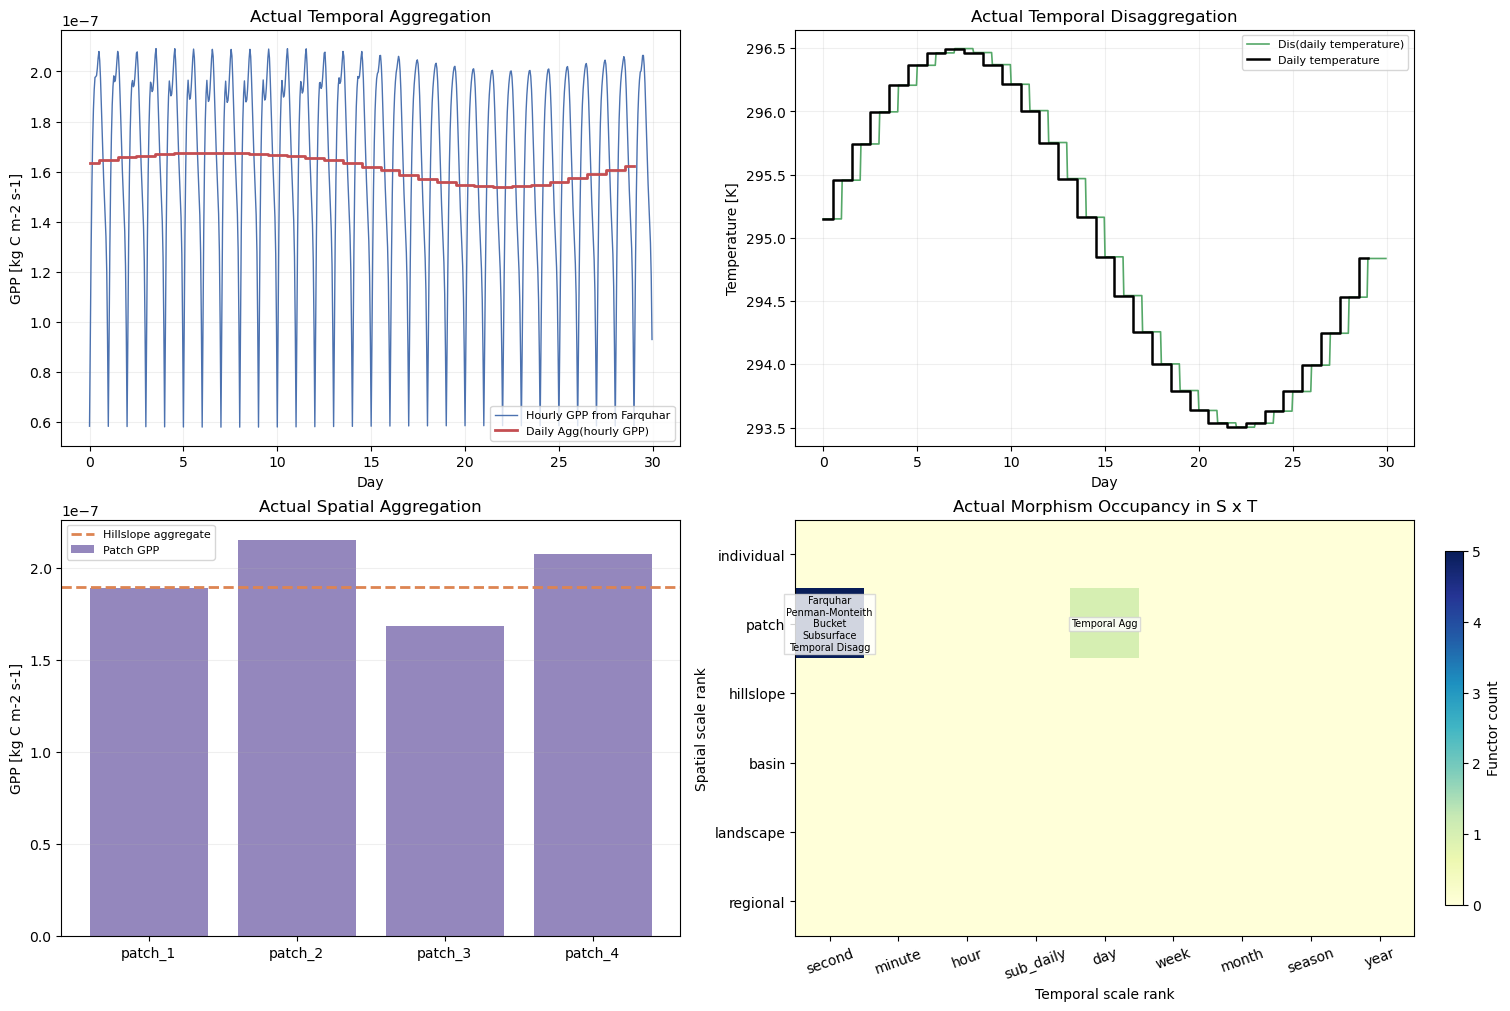

[OK] NB15 visualization now uses actual RELIC aggregation, disaggregation, and metadata-derived scale positions with occupancy-aware labels.


In [7]:
# === NB15: Actual Category-Theory and Scale-Coupling Visualization ===
fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)

hourly_day_axis = ((hourly_time - 0.5) / 24.0).tolist()

ax = axes[0, 0]
ax.plot(hourly_day_axis, gpp_hourly_rate.tolist(), color='#4C72B0', lw=1.0, label='Hourly GPP from Farquhar')
ax.step(range(days), gpp_daily_rate.tolist(), where='mid', color='#C44E52', lw=2.0, label='Daily Agg(hourly GPP)')
ax.set_xlabel('Day')
ax.set_ylabel('GPP [kg C m-2 s-1]')
ax.set_title('Actual Temporal Aggregation')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.2)

ax = axes[0, 1]
ax.plot(hourly_day_axis, temperature_hourly_from_daily.tolist(), color='#55A868', lw=1.2, label='Dis(daily temperature)')
ax.step(range(days), daily_temperature_mean.tolist(), where='mid', color='black', lw=1.8, label='Daily temperature')
ax.set_xlabel('Day')
ax.set_ylabel('Temperature [K]')
ax.set_title('Actual Temporal Disaggregation')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.2)

ax = axes[1, 0]
ax.bar([f'patch_{idx + 1}' for idx in range(patch_gpp.numel())], patch_gpp.tolist(), color='#8172B2', alpha=0.85, label='Patch GPP')
ax.axhline(float(hillslope_gpp[0].item()), color='#DD8452', lw=2.0, ls='--', label='Hillslope aggregate')
ax.set_ylabel('GPP [kg C m-2 s-1]')
ax.set_title('Actual Spatial Aggregation')
ax.legend(fontsize=8)
ax.grid(True, axis='y', alpha=0.2)

ax = axes[1, 1]
scatter_items = [
    ('Farquhar', farquhar_functor),
    ('Penman-Monteith', penman_functor),
    ('Bucket', bucket_functor),
    ('Subsurface', subsurface_functor),
    ('Temporal Agg', gpp_rate_aggregator),
    ('Temporal Disagg', temperature_disaggregator),
]
occupancy = torch.zeros((len(scale_hierarchy), len(temporal_order)), dtype=torch.float32)
cell_labels = {}
for label, item in scatter_items:
    metadata = item.metadata
    x_base = temporal_to_rank.get(resolve_item_temporal_scale(item), -1)
    y_base = scale_to_rank.get(canonical_spatial_scale(metadata.spatial_scale.value), -1)
    occupancy[y_base, x_base] += 1.0
    cell_labels.setdefault((y_base, x_base), []).append(label)
image = ax.imshow(occupancy.tolist(), cmap='YlGnBu', vmin=0.0, vmax=max(1.0, float(torch.max(occupancy).item())), aspect='auto')
for (y_index, x_index), labels in cell_labels.items():
    ax.text(
        x_index,
        y_index,
        chr(10).join(labels),
        ha='center',
        va='center',
        fontsize=7,
        bbox={'facecolor': 'white', 'alpha': 0.82, 'edgecolor': 'lightgray', 'pad': 1.5},
    )
ax.set_xticks(range(len(temporal_order)))
ax.set_xticklabels(temporal_order, rotation=20)
ax.set_yticks(range(len(scale_hierarchy)))
ax.set_yticklabels(scale_hierarchy)
ax.set_xlabel('Temporal scale rank')
ax.set_ylabel('Spatial scale rank')
ax.set_title('Actual Morphism Occupancy in S x T')
ax.grid(False)
plt.colorbar(image, ax=ax, shrink=0.85, label='Functor count')

plt.show()
print('[OK] NB15 visualization now uses actual RELIC aggregation, disaggregation, and metadata-derived scale positions with occupancy-aware labels.')

In [8]:
# ---------------------------------------------------------------
# References:
#   RELIC architecture_overview.md: dependency resolution and registration.
#   Mac Lane (1998), Ch. I: composition.
# Mathematical expression:
#   shared_vars = outputs(F1) intersect inputs(F2); this is a candidate-link screen only
# Parameter meanings:
#   shared_vars: declared common names; units, support, ports and ownership still need validation
# ---------------------------------------------------------------


def check_composition(source_morphism, target_morphism):
    source_metadata = source_morphism.metadata
    target_metadata = target_morphism.metadata
    shared_vars = sorted(set(source_metadata.output_variables) & set(target_metadata.input_variables))
    spatial_match = canonical_spatial_scale(source_metadata.spatial_scale.value) == canonical_spatial_scale(target_metadata.spatial_scale.value)
    temporal_match = resolve_item_temporal_scale(source_morphism) == resolve_item_temporal_scale(target_morphism)
    direct = bool(shared_vars) and spatial_match and temporal_match
    return {
        'pair': f'{source_metadata.name} -> {target_metadata.name}',
        'shared_vars': shared_vars,
        'spatial_match': spatial_match,
        'temporal_match': temporal_match,
        'status': ('DIRECT CANDIDATE; CONTRACT VALIDATION REQUIRED' if direct
                   else ('SCALE DIFFERENCE; DECLARED BRIDGE REQUIRED' if shared_vars
                         else 'NO SHARED VARIABLE; NO DIRECT LINK DECLARED')),
    }


composition_pairs = [
    (penman_functor, bucket_functor),
    (bucket_functor, subsurface_functor),
    (farquhar_functor, bucket_functor),
    (gpp_rate_aggregator, temperature_disaggregator),
]

print('=== Metadata Candidate-Link Screen from Actual RELIC Metadata ===')
for source_morphism, target_morphism in composition_pairs:
    result = check_composition(source_morphism, target_morphism)
    print(f"\n  {result['pair']}")
    print(f"    Shared variables : {result['shared_vars'] if result['shared_vars'] else 'NONE'}")
    print(f"    Spatial match    : {result['spatial_match']}")
    print(f"    Temporal match   : {result['temporal_match']}")
    print(f"    Status           : {result['status']}")

print('\n[OK] Actual metadata identify candidates; this screen does not certify physical composition.')

=== Metadata Candidate-Link Screen from Actual RELIC Metadata ===

  nb15_penman_monteith_et -> nb15_bucket_soil_moisture
    Shared variables : ['evapotranspiration_flux']
    Spatial match    : True
    Temporal match   : True
    Status           : DIRECT CANDIDATE; CONTRACT VALIDATION REQUIRED

  nb15_bucket_soil_moisture -> nb15_subsurface_runoff
    Shared variables : ['drainage_flux', 'soil_moisture']
    Spatial match    : True
    Temporal match   : True
    Status           : DIRECT CANDIDATE; CONTRACT VALIDATION REQUIRED

  nb15_farquhar_photosynthesis -> nb15_bucket_soil_moisture
    Shared variables : NONE
    Spatial match    : True
    Temporal match   : True
    Status           : NO SHARED VARIABLE; NO DIRECT LINK DECLARED

  temporal_aggregator -> temporal_disaggregator
    Shared variables : NONE
    Spatial match    : True
    Temporal match   : False
    Status           : NO SHARED VARIABLE; NO DIRECT LINK DECLARED

[OK] Actual metadata identify candidates; this s

---
## Part 7: Advanced Category Theory Constructs

> **Reference:** `docs/source/theory/spatiotemporal_scale_topology.md` Sections 2.2-3.4
>
> This part checks the weighted-adjoint relation of aggregation and disaggregation
> (Proposition 2.1), draws the fiber-bundle picture (Definition 2.2, a design
> interpretation), and measures a commutation (naturality-style) defect of two
> scale-transfer paths (Section 3.4).


### 7.1 Aggregation and Disaggregation: $RP = I$, $PR \neq I$

**Proposition 2.1** (weighted adjoints): with $R$ the weighted mean and $P$ the broadcast
of Part 5,

$$
\langle Pc, f \rangle_{M_f} = \langle c, Rf \rangle_{M_c}, \qquad R = M_c^{-1} P^{T} M_f .
$$

**Check with the actual temporal operators** (hourly and daily intervals, interval
durations as weights):

1. $RP = I$: disaggregating the daily means to hours and aggregating back returns the
   daily means, up to float32 rounding
2. $PR \neq I$: aggregating the hourly series and broadcasting it back loses the diurnal
   cycle; the error is the within-day variability
3. The duration-weighted ledger $\sum_J A_J (Rf)_J = \sum_i A_i f_i$ (Remark 2.1) keeps the
   interval amount. The theory page treats the adjoint reading as a design interpretation
   that no RELIC component checks; it is not a full categorical adjunction.


In [9]:
# === Weighted-Adjoint Check with Actual RELIC Operators ===
# Reference: Proposition 2.1, docs/source/theory/spatiotemporal_scale_topology.md; RELIC temporal operators.
# Formula: Agg(Dis(X)) ~= X and Dis(Agg(Y)) is a projection onto coarse-resolved information.
# Parameters: X = daily mean temperature, Y = hourly temperature with a diurnal cycle.

temperature_roundtrip_result = temperature_aggregator.aggregate(
    temperature_hourly_from_daily,
    hourly_time,
    daily_time,
    variable_name='air_temperature',
    standard_name='air_temperature',
    units='K',
    time_units='hours since 1970-01-01',
    calendar='noleap',
    source_bounds=hourly_bounds,
    target_bounds=daily_bounds,
    target_units='K',
    measure_units='K hour',
    integration_time_unit='hour',
)
temperature_daily_recovered = temperature_roundtrip_result.data.detach().cpu()
rp_identity_error = float(torch.abs(temperature_daily_recovered - daily_temperature_mean).max().item())

temperature_hourly_projection_result = temperature_disaggregator.disaggregate(
    daily_temperature_mean,
    daily_time,
    hourly_time,
    variable_name='air_temperature',
    standard_name='air_temperature',
    units='K',
    time_units='hours since 1970-01-01',
    calendar='noleap',
    source_bounds=daily_bounds,
    target_bounds=hourly_bounds,
    target_units='K',
    measure_units='K hour',
    integration_time_unit='hour',
)
temperature_hourly_projection = temperature_hourly_projection_result.data.detach().cpu()
temperature_projection_abs_error = torch.abs(temperature_hourly_projection - temperature_hourly)
pr_projection_error = float(torch.max(temperature_projection_abs_error).item())
projection_rmse = float(torch.sqrt(torch.mean((temperature_hourly_projection - temperature_hourly) ** 2)).item())
projection_nrmse = projection_rmse / float(torch.std(temperature_hourly).item())

print('=== Weighted-Adjoint Diagnostics (RP = I, PR != I) ===')
print(f'  RP = I : max|Agg(Dis(T_daily)) - T_daily|  : {rp_identity_error:.6e} K')
print(f'  PR != I: max|Dis(Agg(T_hourly)) - T_hourly|: {pr_projection_error:.6e} K')
print(f'  Projection RMSE                        : {projection_rmse:.6e} K')
print(f'  Projection NRMSE / sigma(T_hourly)     : {projection_nrmse:.6e}')
print('[OK] RP = I holds to float32 rounding; PR != I removes the diurnal cycle of the actual temperature signal.')
# Units: Temperature errors are K; the tolerance is an explicit float32 rounding allowance.
# Domain/constraints: Complete nested hourly/daily intervals and fixed weights.
# Sign convention: Reported errors are nonnegative absolute differences.
rounding_allowance = 8.0 * torch.finfo(temperature_daily_recovered.dtype).eps * float(torch.max(torch.abs(daily_temperature_mean)))
assert rp_identity_error <= rounding_allowance
assert pr_projection_error > 0.0, 'The nonconstant hourly signal must lose its within-day pattern.'


=== Weighted-Adjoint Diagnostics (RP = I, PR != I) ===
  RP = I : max|Agg(Dis(T_daily)) - T_daily|  : 3.051758e-05 K
  PR != I: max|Dis(Agg(T_hourly)) - T_hourly|: 6.591705e+00 K
  Projection RMSE                        : 4.596641e+00 K
  Projection NRMSE / sigma(T_hourly)     : 9.738088e-01
[OK] RP = I holds to float32 rounding; PR != I removes the diurnal cycle of the actual temperature signal.


### 7.2 Fiber-Bundle Picture (design interpretation)

**Definition 2.2** (interpretation, not implemented): the multi-scale state space can be
pictured as a fiber bundle

$$\pi: E \to B$$

whose fiber over a scale is the set of variables declared at that scale. The theory page
uses the spatial scale labels as the base $B$; the figure below uses base points $(s, t)$
of $\mathcal{S} \times \mathcal{T}$ taken from each Functor's metadata and lists the
declared outputs as the fiber.

RELIC stores scale labels per Functor; it does not store fibers, a connection, or a
curvature. Definition 2.3 reads regridding as the "connection" only as an interpretation:
composed remaps generally differ from a direct remap unless the grids are nested.


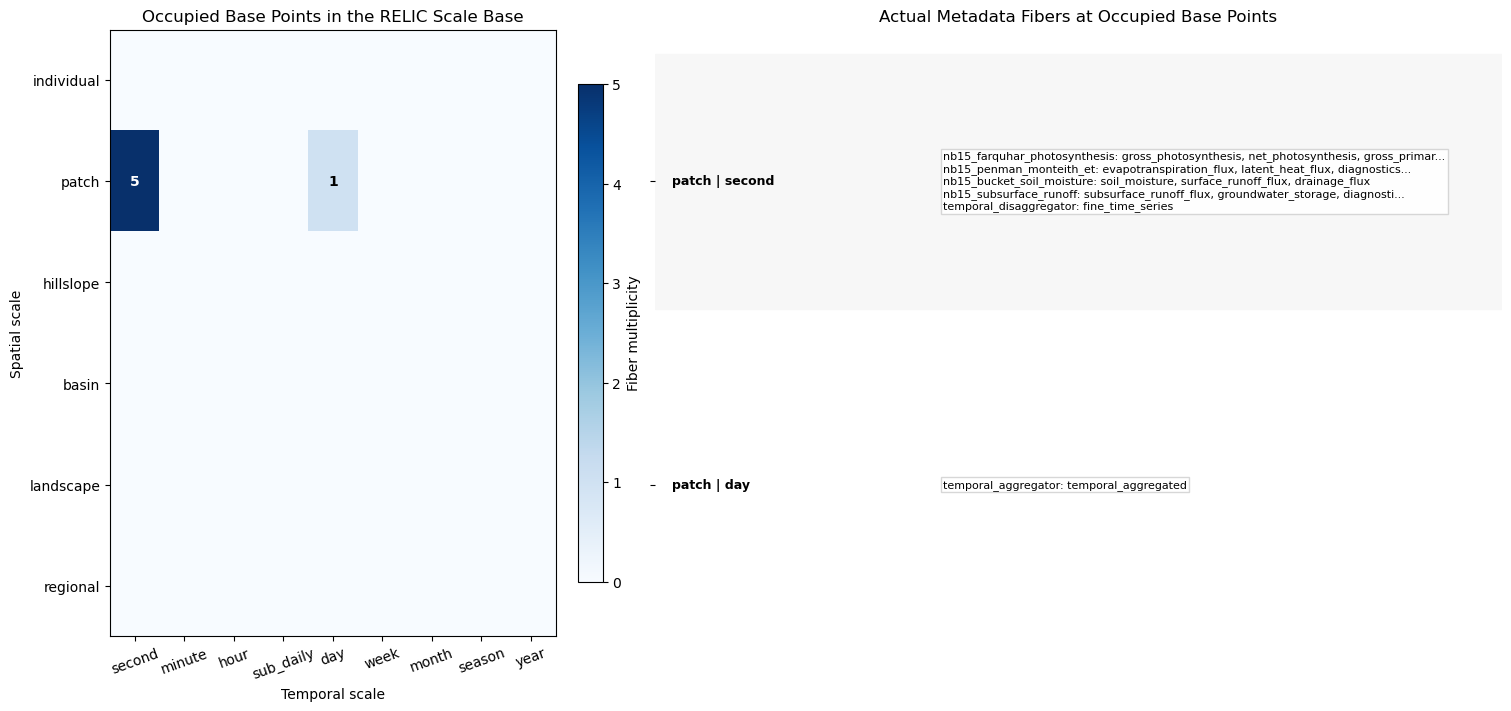

[OK] Fiber-bundle style visualization now groups actual RELIC metadata by occupied base point instead of spreading sparse labels across an oversized scale grid.


In [10]:
# === Fiber Bundle Structure from Actual RELIC Metadata ===
# Reference: RELIC FunctorMetadata and the configured scale hierarchy.
# Formula: each base point (s, t) carries a fiber of actual state/flux variables.
# Parameters: outputs(metadata) = representative fiber labels at each base point.

fiber_items = [farquhar_functor, penman_functor, bucket_functor, subsurface_functor, gpp_rate_aggregator, temperature_disaggregator]
fiber_groups = {}
occupancy = torch.zeros((len(scale_hierarchy), len(temporal_order)), dtype=torch.float32)
for item in fiber_items:
    metadata = item.metadata
    x_base = temporal_to_rank.get(resolve_item_temporal_scale(item), -1)
    y_base = scale_to_rank.get(canonical_spatial_scale(metadata.spatial_scale.value), -1)
    occupancy[y_base, x_base] += 1.0
    output_preview = ', '.join(list(metadata.output_variables)[:3])
    if not output_preview:
        output_preview = 'metadata-only'
    fiber_groups.setdefault((y_base, x_base), []).append((metadata.name, output_preview))

occupied_keys = sorted(fiber_groups.keys(), key=lambda pair: (pair[0], pair[1]))
fig, axes = plt.subplots(1, 2, figsize=(15, 7), constrained_layout=True, gridspec_kw={'width_ratios': [1.0, 1.9]})

grid_ax = axes[0]
image = grid_ax.imshow(occupancy.tolist(), cmap='Blues', vmin=0.0, vmax=max(1.0, float(torch.max(occupancy).item())), aspect='auto')
for (y_index, x_index), items in fiber_groups.items():
    grid_ax.text(x_index, y_index, str(len(items)), ha='center', va='center', fontsize=10, fontweight='bold', color='white' if image.norm(float(len(items))) > 0.5 else 'black')
grid_ax.set_xticks(range(len(temporal_order)))
grid_ax.set_xticklabels(temporal_order, rotation=20)
grid_ax.set_yticks(range(len(scale_hierarchy)))
grid_ax.set_yticklabels(scale_hierarchy)
grid_ax.set_xlabel('Temporal scale')
grid_ax.set_ylabel('Spatial scale')
grid_ax.set_title('Occupied Base Points in the RELIC Scale Base')
grid_ax.grid(False)
plt.colorbar(image, ax=grid_ax, shrink=0.82, label='Fiber multiplicity')

detail_ax = axes[1]
detail_ax.set_xlim(0.0, 1.0)
detail_ax.set_ylim(len(occupied_keys) - 0.5, -0.5)
detail_ax.set_xticks([])
detail_ax.set_yticks(range(len(occupied_keys)))
detail_ax.set_yticklabels([])
detail_ax.set_title('Actual Metadata Fibers at Occupied Base Points')
for row_index, (y_index, x_index) in enumerate(occupied_keys):
    background_color = '#F7F7F7' if row_index % 2 == 0 else '#FFFFFF'
    detail_ax.axhspan(row_index - 0.42, row_index + 0.42, color=background_color, zorder=0)
    base_label = f"{scale_hierarchy[y_index]} | {temporal_order[x_index]}"
    detail_ax.text(0.02, row_index, base_label, ha='left', va='center', fontsize=9, fontweight='bold')
    detail_lines = []
    for metadata_name, output_preview in fiber_groups[(y_index, x_index)]:
        short_preview = output_preview[:54] + '...' if len(output_preview) > 54 else output_preview
        detail_lines.append(f"{metadata_name}: {short_preview}")
    detail_ax.text(
        0.34,
        row_index,
        chr(10).join(detail_lines),
        ha='left',
        va='center',
        fontsize=8,
        bbox={'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'lightgray', 'pad': 1.6},
    )
for spine in detail_ax.spines.values():
    spine.set_visible(False)

plt.show()
print('[OK] Fiber-bundle style visualization now groups actual RELIC metadata by occupied base point instead of spreading sparse labels across an oversized scale grid.')

### 7.3 Naturality as a Commutation Test

**Definition 3.3** (interpretation): a coupling $\eta: F \Rightarrow G$ between two
Functors would be natural if every naturality square commutes:

```
    F(A) ---eta_A---> G(A)
     |                 |
   F(f)              G(f)
     |                 |
     v                 v
    F(B) ---eta_B---> G(B)
```

$$G(f) \circ \eta_A = \eta_B \circ F(f)$$

RELIC does not assume that couplings are natural and does not check this square. What can
be measured is a commutation defect such as
$\epsilon = \lVert \mathrm{Agg}(F(x)) - F(\mathrm{Agg}(x)) \rVert$. The cell below compares
two paths through the spatial and temporal aggregation of actual Farquhar GPP:
space-then-time and time-then-space. Both are weighted means with fixed normalized
weights, so they commute and the defect is rounding-level. For a nonlinear process $F$
(photosynthesis on aggregated inputs versus aggregated photosynthesis) the defect is
generally non-zero (Jensen gap).


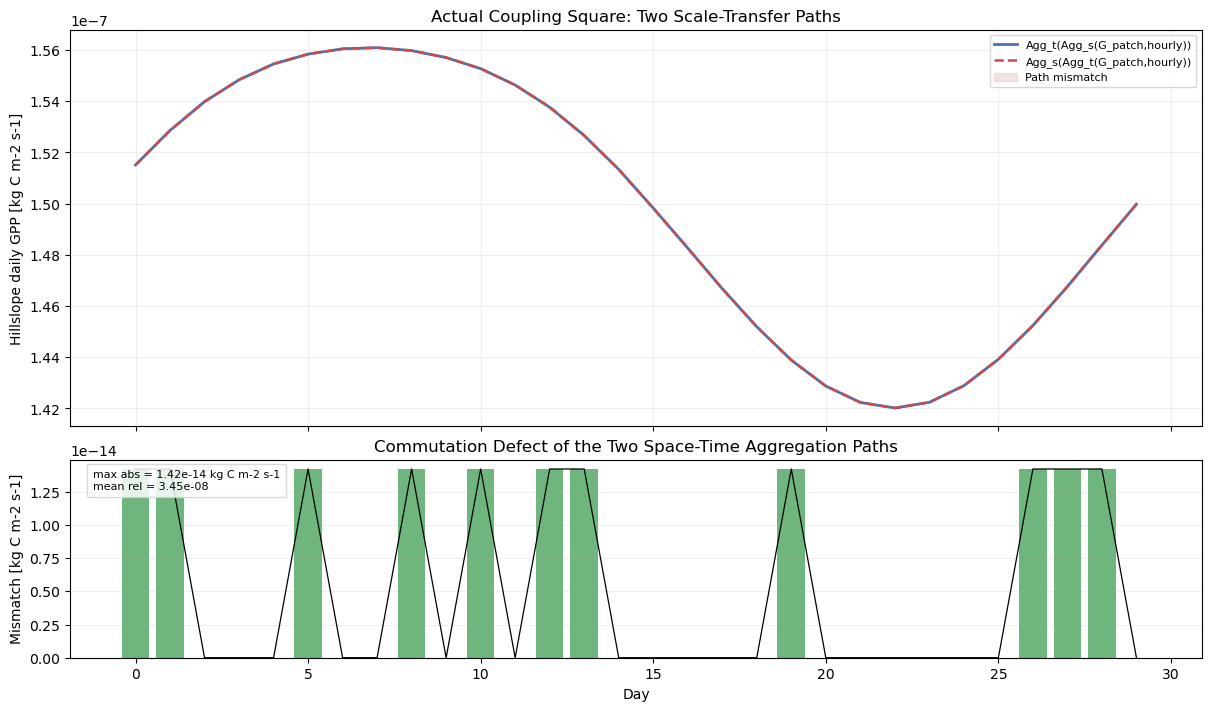

=== Actual Naturality-Style Coupling Diagnostics ===
  Mediator phase                : READY
  Negotiated coupling dt [s]    : 3600.0
  Last hourly ledger rel. resid.: 8.423239e-08 (accepted: True)
  Last daily ledger rel. resid. : 0.000000e+00 (accepted: True)
  Mean commutation defect       : 5.210647e-15 kg C m-2 s-1
  Max commutation defect        : 1.421085e-14 kg C m-2 s-1
  Mean relative defect          : 3.451033e-08
  Captured Farquhar diagnostics : 0
  Note                          : standalone leaf-level calls capture diagnostics locally before the multi-scale comparison is summarized.
[OK] The coupling square now compares two actual RELIC space-time aggregation paths on real Farquhar-derived GPP.


In [11]:
# === Naturality-Style Coupling Check with Actual RELIC Operators ===
# Reference: category-theory naturality interpreted through actual RELIC spatial and temporal aggregation.
# Formula: Agg_t(Agg_s(G_patch,hourly)) versus Agg_s(Agg_t(G_patch,hourly))
# Parameters:
#   path_space_then_time: hillslope daily GPP after hourly spatial aggregation followed by temporal aggregation
#   path_time_then_space: hillslope daily GPP after patchwise temporal aggregation followed by spatial aggregation
#   naturality_error_series: daily mismatch between the two actual scale-transfer paths
# Units: GPP and mismatch [kg C m-2 s-1]; relative mismatch [dimensionless].
# Domain/constraints: both paths are weighted means with fixed normalized weights, so the
#   expected mismatch is floating-point rounding; the hourly and daily spatial aggregations
#   use the catalog variable gross_primary_productivity (area_density).
# Sign convention: mismatch is an absolute difference (non-negative).

patch_par_factors = torch.tensor([0.92, 1.08, 0.85, 1.00], dtype=torch.float32)
patch_temperature_offsets = torch.tensor([-0.8, 0.7, -1.1, 0.4], dtype=torch.float32)
patch_hourly_gpp_series = []
for patch_index in range(patch_areas.numel()):
    patch_outputs = run_farquhar_response(
        par=par_hourly * patch_par_factors[patch_index],
        temperature=temperature_hourly + patch_temperature_offsets[patch_index],
        leaf_area_index=float(patch_lai[patch_index].item()),
        name=f'nb15_patch_hourly_{patch_index}',
    )
    patch_hourly_gpp_series.append(patch_outputs['gross_primary_productivity'])
patch_hourly_gpp = torch.stack(patch_hourly_gpp_series, dim=0)

hillslope_hourly_gpp = []
for hour_index in range(hours):
    aggregated_hour, aggregated_hour_audit = scale_manager_runtime.aggregate(
        patch_hourly_gpp[:, hour_index],
        source_scale='patch',
        target_scale='hillslope',
        variables=['gross_primary_productivity'],
        strategy=ScalingStrategy.AREA_WEIGHTED_MEAN,
        topology=patch_topology,
    )
    hillslope_hourly_gpp.append(aggregated_hour.detach().cpu().reshape(-1)[0])
hillslope_hourly_gpp = torch.stack(hillslope_hourly_gpp)

path_space_then_time = gpp_rate_aggregator.aggregate(
    hillslope_hourly_gpp,
    hourly_time,
    daily_time,
    variable_name='gross_primary_productivity',
    standard_name='gross_primary_productivity',
    units='kg C m-2 s-1',
    time_units='hours since 1970-01-01',
    calendar='noleap',
    source_bounds=hourly_bounds,
    target_bounds=daily_bounds,
    target_units='kg C m-2 s-1',
    measure_units='kg C m-2',
    integration_time_unit='s',
).data.detach().cpu()

patch_daily_gpp = []
for patch_index in range(patch_areas.numel()):
    patch_daily_result = gpp_rate_aggregator.aggregate(
        patch_hourly_gpp[patch_index],
        hourly_time,
        daily_time,
        variable_name='gross_primary_productivity',
        standard_name='gross_primary_productivity',
        units='kg C m-2 s-1',
        time_units='hours since 1970-01-01',
        calendar='noleap',
        source_bounds=hourly_bounds,
        target_bounds=daily_bounds,
        target_units='kg C m-2 s-1',
        measure_units='kg C m-2',
        integration_time_unit='s',
    )
    patch_daily_gpp.append(patch_daily_result.data.detach().cpu())
patch_daily_gpp = torch.stack(patch_daily_gpp, dim=0)

path_time_then_space = []
for day_index in range(days):
    aggregated_day, aggregated_day_audit = scale_manager_runtime.aggregate(
        patch_daily_gpp[:, day_index],
        source_scale='patch',
        target_scale='hillslope',
        variables=['gross_primary_productivity'],
        strategy=ScalingStrategy.AREA_WEIGHTED_MEAN,
        topology=patch_topology,
    )
    path_time_then_space.append(aggregated_day.detach().cpu().reshape(-1)[0])
path_time_then_space = torch.stack(path_time_then_space)

naturality_error_series = torch.abs(path_space_then_time - path_time_then_space)
relative_naturality_error = naturality_error_series / torch.clamp(torch.abs(path_space_then_time), min=1.0e-9)

import_state = State('nb15_scale_import')
import_state.add_field(
    'patch_gpp_hourly',
    Field(name='patch_gpp_hourly', data=patch_hourly_gpp, standard_name='gross_primary_productivity', units='kg C m-2 s-1', semantics='flux'),
    direction='import',
)
export_state = State('nb15_scale_export')
export_state.add_field(
    'hillslope_gpp_daily',
    Field(name='hillslope_gpp_daily', data=path_space_then_time, standard_name='gross_primary_productivity', units='kg C m-2 s-1', semantics='flux'),
    direction='export',
)
mediator = Mediator(import_state=import_state, export_state=export_state)
mediator.advertise({'patch_gpp_hourly', 'hillslope_gpp_daily'})
mediator.realize(validate_all=True)
mediator.data_initialize({'patch_gpp_hourly': patch_hourly_gpp})
mediator.complete_initialization()

clock_negotiator = TimeStagger(lag_seconds=0.0, lead_seconds=0.0)
clock_negotiator.register_clock('hourly_patch', ClockConfig(time_step=1.0, unit=TimeUnit.HOURS))
clock_negotiator.register_clock('daily_hillslope', ClockConfig(time_step=1.0, unit=TimeUnit.DAYS))
negotiated_dt = clock_negotiator.negotiate(strategy='gcd')

days_axis = list(range(days))
naturality_error_values = naturality_error_series.tolist()
summary_text = 'max abs = ' + f"{float(torch.max(naturality_error_series).item()):.2e}" + ' kg C m-2 s-1' + chr(10) + 'mean rel = ' + f"{float(torch.mean(relative_naturality_error).item()):.2e}"

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 7),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={'height_ratios': [2.0, 1.0]},
)

axes[0].plot(days_axis, path_space_then_time.tolist(), color='#4C72B0', lw=2.0, label='Agg_t(Agg_s(G_patch,hourly))')
axes[0].plot(days_axis, path_time_then_space.tolist(), color='#C44E52', lw=1.8, ls='--', label='Agg_s(Agg_t(G_patch,hourly))')
axes[0].fill_between(days_axis, path_space_then_time.tolist(), path_time_then_space.tolist(), color='#C44E52', alpha=0.15, label='Path mismatch')
axes[0].set_ylabel('Hillslope daily GPP [kg C m-2 s-1]')
axes[0].set_title('Actual Coupling Square: Two Scale-Transfer Paths')
axes[0].legend(fontsize=8, loc='upper right')
axes[0].grid(True, alpha=0.2)

axes[1].bar(days_axis, naturality_error_values, color='#55A868', alpha=0.85)
axes[1].plot(days_axis, naturality_error_values, color='black', lw=0.9)
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Mismatch [kg C m-2 s-1]')
axes[1].set_title('Commutation Defect of the Two Space-Time Aggregation Paths')
axes[1].grid(True, axis='y', alpha=0.2)
axes[1].text(
    0.02,
    0.95,
    summary_text,
    transform=axes[1].transAxes,
    va='top',
    fontsize=8,
    bbox={'facecolor': 'white', 'alpha': 0.85, 'edgecolor': 'lightgray'},
)

plt.show()
print('=== Actual Naturality-Style Coupling Diagnostics ===')
print(f'  Mediator phase                : {mediator.phase.name}')
print(f'  Negotiated coupling dt [s]    : {negotiated_dt:.1f}')
hour_ledger = aggregated_hour_audit.metadata['conservation_audit']['gross_primary_productivity']
day_ledger = aggregated_day_audit.metadata['conservation_audit']['gross_primary_productivity']
print(f'  Last hourly ledger rel. resid.: {hour_ledger.relative_error:.6e} (accepted: {hour_ledger.is_conserved})')
print(f'  Last daily ledger rel. resid. : {day_ledger.relative_error:.6e} (accepted: {day_ledger.is_conserved})')
print(f'  Mean commutation defect       : {float(torch.mean(naturality_error_series).item()):.6e} kg C m-2 s-1')
print(f'  Max commutation defect        : {float(torch.max(naturality_error_series).item()):.6e} kg C m-2 s-1')
print(f'  Mean relative defect          : {float(torch.mean(relative_naturality_error).item()):.6e}')
print(f'  Captured Farquhar diagnostics : {sum(farquhar_warning_counts.values())}')
print('  Note                          : standalone leaf-level calls capture diagnostics locally before the multi-scale comparison is summarized.')
print('[OK] The coupling square now compares two actual RELIC space-time aggregation paths on real Farquhar-derived GPP.')
assert hour_ledger.is_conserved and day_ledger.is_conserved
assert torch.allclose(path_space_then_time, path_time_then_space,
                      rtol=64.0 * torch.finfo(path_space_then_time.dtype).eps, atol=0.0)


## Summary: Category Theory in RELIC

| Concept | Math | RELIC Implementation |
|---|---|---|
| Objects | $\text{Ob}(\mathcal{C})$ | State variable declarations |
| Morphisms | $f : A \to B$ | `forward()` run through `FunctorBase.__call__` |
| Composition | $g \circ f$ | Dependency-ordered execution |
| Identity | $\text{id}_A$ | Zero-increment map (an interpretation; not enforced) |
| Scale Lattice | $(\mathcal{S}, \preceq)$ | `get_scale_hierarchy()` order (`coupling.scales.hierarchy.levels`); `SpatialScale` labels carry no order |
| Product Category | $\mathcal{S} \times \mathcal{T}$ | `(spatial_scale, temporal_scale)` |
| Aggregation / Disaggregation | Weighted adjoints, $RP = I$, $PR \neq I$ | `TemporalAggregator`, `TemporalDisaggregator`, `ScaleManager.aggregate` |
| Composition checks | Morphism compatibility | Dependency and output-overlap checks at registration; scale checks per execution group with `enable_auto_scale` or `strict_scale_detection` |

### The Three Pillars of RELIC's Design Safety

1. **NB13**: Structural invariants survive chaos (motivation)
2. **NB14**: DEC gives computable structural invariants ($\sigma, \kappa, \beta_1$)
3. **NB15**: Category theory organises these invariants into a composable framework

Together, they form RELIC's **structuralist** approach to Earth system modeling:
validate **structure** alongside physical budgets, numerical accuracy and
observational evidence. The display aliases and candidate-link screen are
not additional framework owners or certification gates.
